#Sentiment_Analysis

**Loading Libraries**

In [267]:
# Basic Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Text Processing
import re
import spacy

# Machine Learning
from sklearn.feature_extraction.text import CountVectorizer

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Load English language NLP Model
nlp = spacy.load("en_core_web_sm")

In [268]:
# Loading the data set
df = pd.read_excel("/content/dataset.xlsx")

In [269]:
df.head()

,title,rating,body
0,Horrible product,1,Very disappointed with the overall performance...
1,Camera quality is not like 48 megapixel,3,Camera quality is low
2,Overall,4,"Got the mobile on the launch date,Battery must..."
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp..."


In [270]:
hindi_reviews = df['body'].str.contains(r'[\u0900-\u097F]', na=False).sum()
print(hindi_reviews)

12


In [271]:
hindi_rows = df[
    df['title'].str.contains(r'[\u0900-\u097F]', na=False) |
    df['body'].str.contains(r'[\u0900-\u097F]', na=False)
]

print(hindi_rows)

                                                  title  rating  \
7                       कैसा दिखाते है उसका 10 % भी नही       1   
248                             Damage product reshived       1   
421   अमेज़न आपके द्वारा खरीदा samsung m12 6GB ram 12...       1   
460                                           असंतोषजनक       1   
524                        पैसे की बर्बादी है ये मोबाइल       2   
700         सैमसंग के मोबाइल के मेरे लिए बेस्ट रहते है।       4   
794                    इस फोन में बहुत सारे प्रॉब्लम है       1   
803                            Samsung worst phone ever       1   
887                       बकबास फ़ोन,  पैसे खड्डे में गए       1   
1051                                              कैमरा       1   
1301                                         Very bad 👎       1   
1369  बहुत ही अच्छा कैमरा और बैटरी बैकअप है इस फोन क...       5   

                                                   body  
7     मोबाइल का कैमरा बिल्कुल भी सही नही है 48 PM बत...  
248   Damage

In [272]:
translations = {
    7: {
        "title": "Not Even 10% as Good as Advertised",
        "body": "The phone's camera is extremely poor. Although it is advertised as 48 MP, the quality is not even comparable to a 5 MP camera. The phone also looks outdated. Do not buy it."
    },

    248: {
        "title": "Received a Damaged Product",
        "body": "I received a damaged product, and no help was provided. I ordered it from Amazon, but even after 20 days there has been no service or pickup. The order is still pending, and my payment has already been deducted."
    },

    421: {
        "title": "Disappointed with Samsung M12",
        "body": "I purchased the Samsung M12 with 6GB RAM, 128GB storage, and a 6000mAh battery from Amazon. I have no complaints about Amazon, but I am disappointed with Samsung. I had been using the Samsung J6 for the past two years and it was an excellent phone except for the battery. Compared to it, I am not satisfied with the M12."
    },

    460: {
        "title": "Unsatisfactory",
        "body": "This phone has several issues. The notification sound continues even after turning it off. There is no charging indicator while charging. It also lacks a notification LED, so you cannot know if a notification arrives when the screen is locked. The phone is heavy, the camera quality is disappointing despite having four cameras, and the Wi-Fi signal becomes weak after passing through a wall."
    },

    524: {
        "title": "Waste of Money",
        "body": "The so-called 48 MP camera is completely fake. Its quality is similar to an old 2 MP camera. Apart from the battery, there is nothing impressive about this phone. Many better options are available in this price range. I don't understand why Amazon still shows a 4.5-star rating despite so many customers giving it 1 star."
    },

    700: {
        "title": "Samsung Phones Have Always Been the Best for Me",
        "body": "This is a good Samsung 5G phone. Earlier I used the Samsung On5, then the Samsung J7 Max, and now I am using the Samsung M42 5G with 8GB RAM and 128GB storage. I have never faced any problems with Samsung phones. You can confidently buy this phone. I also bought the Samsung M12 for my family, and it is a good device."
    },

    794: {
        "title": "This Phone Has Many Problems",
        "body": "This phone has many issues. It switches off automatically while charging and takes hours to turn back on. I do not recommend buying it. You may also receive a used phone with display defects. Overall, this phone has many serious problems."
    },

    803: {
        "title": "Samsung's Worst Phone Ever",
        "body": "The Dual App feature does not work properly. The second WhatsApp does not display data, media files disappear, and photos are automatically deleted from folders. Samsung has not provided a solution even after six months. Even Chinese brands provide better software support. Please do not buy any Samsung M-series phone. It is a complete waste of money."
    },

    887: {
        "title": "Worst Phone - Complete Waste of Money",
        "body": "Worst phone ever. The screenshot feature is terrible. While taking a screenshot, the phone suddenly entered Safe Mode. Even after deleting the data, it would not start properly. Charging is also extremely slow."
    },

    1051: {
        "title": "Terrible Camera Quality",
        "body": "The camera on this phone is extremely poor and does not match the company's claims. The first image was taken using this phone, while the second image was taken using my Realme 6 Pro. I did not like this phone at all because of its camera performance."
    },

    1301: {
        "title": "Very Bad",
        "body": "The camera quality is extremely poor. The battery does not charge properly. The phone is heavy and bulky, making it uncomfortable to use. The processor is also weak. Overall, the phone does not deliver the performance promised by the company."
    },

    1369: {
        "title": "Excellent Camera and Battery Backup",
        "body": "The media could not be loaded. Overall, I really liked this phone. The camera quality and battery backup are excellent. Despite a few minor shortcomings, I am satisfied with the phone."
    }
}

# Update the dataframe
for idx, values in translations.items():
    df.loc[idx, "title"] = values["title"]
    df.loc[idx, "body"] = values["body"]

print("All 12 Hindi reviews have been translated and updated successfully.")

All 12 Hindi reviews have been translated and updated successfully.


In [273]:
df.loc[[7,248,421,460,524,700,794,803,887,1051,1301,1369], ['title','body']]

,title,body
7,Not Even 10% as Good as Advertised,The phone's camera is extremely poor. Although...
248,Received a Damaged Product,"I received a damaged product, and no help was ..."
421,Disappointed with Samsung M12,"I purchased the Samsung M12 with 6GB RAM, 128G..."
460,Unsatisfactory,This phone has several issues. The notificatio...
524,Waste of Money,The so-called 48 MP camera is completely fake....
700,Samsung Phones Have Always Been the Best for Me,This is a good Samsung 5G phone. Earlier I use...
794,This Phone Has Many Problems,This phone has many issues. It switches off au...
803,Samsung's Worst Phone Ever,The Dual App feature does not work properly. T...
887,Worst Phone - Complete Waste of Money,Worst phone ever. The screenshot feature is te...
1051,Terrible Camera Quality,The camera on this phone is extremely poor and...


**Data-Set Overview**

The above dataset is an Amazon customer reviews dataset. It contains reviews provided by customers based on the products they purchased from Amazon. Each review includes the product title, customer rating, and written feedback reflecting the customer's experience with the product.

The dataset consists of three columns:

1. Title: Represents the title or summary of the customer's review.
2. Rating: Represents the rating given by the customer to the product based on their experience.('5' means 5 star rating)
3. Body: Contains the detailed review or overall experience shared by the customer about the product.

**This project aims to perform sentiment analysis by classifying each customer review into one of three categories: Positive, Negative, or Neutral, based on the content of the review.**

In [274]:
def sentiment(rating):
    if rating >= 4:
        return "Positive"
    elif rating == 3:
        return "Neutral"
    else:
        return "Negative"

df["sentiment"] = df["rating"].apply(sentiment)

#EDA

In [275]:
rows,columns = df.shape
print(f'Total rows:- {rows}')
print(f'Total columns:- {columns}')

Total rows:- 1440
Total columns:- 4


In [276]:
print(f'Total elements inside the data set :- {df.size}')

Total elements inside the data set :- 5760


In [277]:
# Checking duplicates
df.duplicated().sum()

np.int64(0)

No duplicate value inside the data set

In [278]:
# checking null values
df.isnull().sum()

,0
title,0
rating,0
body,0
sentiment,0


No null values inside the data set

**User_rating**

In [279]:
# Unique value inside the data set
np.sort(df["rating"].unique())

array([1, 2, 3, 4, 5])

In [280]:
# Total count for each rating individually
df.rating.value_counts()

,count
rating,
5,419
1,386
4,310
3,199
2,126


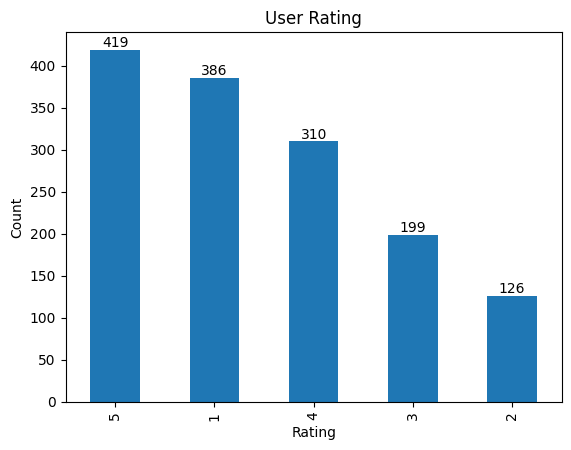

In [281]:
ax = df.rating.value_counts().sort_values(ascending=False).plot(kind='bar')
for i in ax.containers:
  ax.bar_label(i)
  plt.title('User Rating')
  plt.xlabel('Rating')
  plt.ylabel('Count')
  plt.show()

"From the rating distribution, we can see that 5-star ratings have the highest count (419), followed by 1-star ratings (386) and 4-star ratings (310). This indicates that while many customers had an excellent experience, a significant number also had a poor experience. However, if we combine the positive ratings (4 and 5 stars), they account for 729 reviews, which is much higher than the combined negative ratings (1 and 2 stars) with 512 reviews. Therefore, overall customer sentiment appears to be more positive than negative."

In [282]:
# Distribution of rating with the help of the pie chart

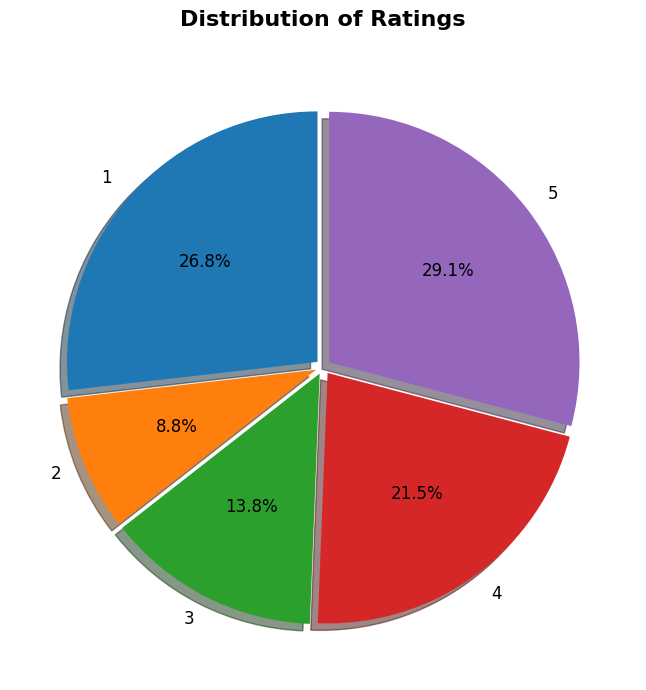

In [283]:
plt.figure(figsize=(7,7))

rating_counts = df["rating"].value_counts().sort_index()

explode = [0.03] * len(rating_counts)

rating_counts.plot(
    kind="pie",
    autopct="%.1f%%",
    startangle=90,
    explode=explode,
    shadow=True,
    textprops={"fontsize":12},
)

plt.title("Distribution of Ratings", fontsize=16, fontweight="bold", pad=20)
plt.ylabel("")
plt.tight_layout()
plt.show()

**Longest review**

In [284]:
# Calculating the length of each review.
# Create a new column to store the total number of characters in each review.
df['Review_length'] = df['body'].apply(len)
df.head()

,title,rating,body,sentiment,Review_length
0,Horrible product,1,Very disappointed with the overall performance...,Negative,59
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Neutral,21
2,Overall,4,"Got the mobile on the launch date,Battery must...",Positive,403
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,Negative,377
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Negative,179


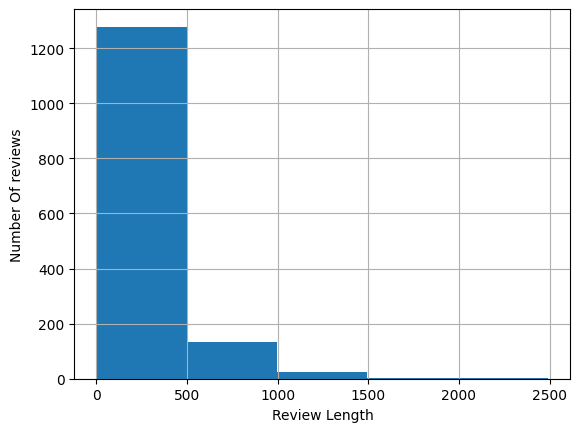

In [285]:
# Histogram of Review Length
# A histogram shows how review lengths are distributed.

df['Review_length'].hist(bins = 5)
plt.xlabel('Review Length')
plt.ylabel('Number Of reviews')
plt.show()

**Longest_review in the entire data set**

In [286]:
df.Review_length.max() # total charater inside the longest review

2490

In [287]:
df[df.Review_length == df.Review_length.max()]

,title,rating,body,sentiment,Review_length
23,"Not So impressive,okay okay.Little over price",3,The media could not be loaded.\n ...,Neutral,2490


In [288]:
Longest_review = df.loc[df['Review_length'].idxmax()]
print(Longest_review['body']) # longest review
print(len(Longest_review))

The media could not be loaded.
                




   #m12,#m12unboxing,#samsungm12 ,#unboxing ,#Samsung, #Galaxy, #M12,#SamsungGalaxyM12M12 unboxing videoNot so impressive Mobile from Samsung, currently direct compete with LGK42, Moto G30/G10To All people who want to purchase mobile DO NOT go on Mobile Marketing and Actors endorsing Mobile.:Remember 5G is coming hence you are getting so much discount on all 4G mobile. Mobile manufacturers are clearing stocks, Need to inform 5G mobile support 4G band but all 4G mobile will not support 5G.Take example, if you purchase 20,0000 mobile today, after 20 months you may need to change to 5G mobile hence it will cost you 1000 per month (costing matters) and you will not get High exchange value (not even 50% cost), Currently 5G yet to come in India, may be yearend or come will be high cost.Points to Remember while purchasing Mobile:1) Mobile band support, Dual Wi-fi Support is better.2) Graphics PPI matter hence check PPI value of mobile. It di

**Smallest_Review in the entire data set**

In [289]:
df.Review_length.min() # total charater inside the smallest review

4

In [290]:
df[df.Review_length == df.Review_length.min()]

,title,rating,body,sentiment,Review_length
1106,Good,5,Like,Positive,4


In [291]:
Shortest_review = df.loc[df['Review_length'].idxmin()]
print(Shortest_review['body']) # shortest review

Like


**Longest and shortest review in the entire data set**

Positive

In [292]:
positive_reviews = df[df["sentiment"] == "Positive"]

longest_positive = positive_reviews.loc[positive_reviews["Review_length"].idxmax()]

print(longest_positive["body"])
print("Total characters:", len(longest_positive["body"]))

New year and Christmas day special status quotes wishes<a href="https://www.best-status.com/2017/10/best-10-happy-new-year-2018-gif-image.html"> Happy New year Gif image </a><a href="https://www.best-status.com/2017/12/happy-christmas-merry-christmas-status-wishes-for-whatsapp.html">Happy Christmas status wishes for WhatsApp</a><a href="https://www.best-status.com/2017/10/happy-christmas-day-hindi-status.html">Happy Christmas day Hindi status </a><a href="https://www.best-status.com/2017/11/happy-christmas-status-and-merry.html">happy Christmas status Gif image picture </a><a href="https://www.best-status.com/2017/12/happy-new-year-and-merry-christmas.html">Happy new year and merry Christmas status</a><a href="https://www.best-status.com/2017/12/romantic-new-year-2018-statusmassage.html">Romantic new year status massage </a><a href="https://www.best-status.com/2017/12/happy-new-year-2018-gifs-animated-image.html"> happy new year Gif image picture animated </a><a href="https://www.best-

In [293]:
Shortest_pos_review = positive_reviews.loc[positive_reviews['Review_length'].idxmin()]
print(Shortest_pos_review['body']) # shortest review

Like


Negative

In [294]:
negative_reviews = df[df["sentiment"] == "Negative"]

longest_negative = negative_reviews.loc[negative_reviews["Review_length"].idxmax()]

print("Longest Negative Review:\n")
print(longest_negative["body"])
print("\nTotal Characters:", len(longest_negative["body"]))

Longest Negative Review:

The media could not be loaded.
                




   I had received this phone on 09th May 2021. For first two days it worked ok. (OK because this phone is very slow)BUT on third day, 12th May 2021, it was hanged very badly. It was neither getting switched off nor restarted..!!Immediately I have contacted the customer care for its solution. The Amazon representative has responded well and helped me to book technician's visit, which has completed on 15th May 2021.Amazon is ready for its replacement according to their 7 days replacement policy and hand to hand replacement.It was a traumatic condition for me as I have bought this phone in this COVID pandemic in very urgent condition and I badly need a phone always working 24X7 as my family was admitted in the hospital.Also, people who wish to buy it for its Camera then please beware as Samsung is advertising it as TRUE 48MP QUAD CAMERA but its result is like 8MP blurred one.Second thing is the phone is very slo

In [295]:
Shortest_neg_review = negative_reviews.loc[negative_reviews['Review_length'].idxmin()]
print(Shortest_neg_review['body']) # shortest review
print(len(Shortest_neg_review['body']))

Dislike
7


Neutral

In [296]:
neutral_reviews = df[df["sentiment"] == "Neutral"]

longest_neutral = neutral_reviews.loc[neutral_reviews["Review_length"].idxmax()]

print("Longest Neutral Review:\n")
print(longest_neutral["body"])
print("\nTotal Characters:", len(longest_neutral["body"]))

Longest Neutral Review:

The media could not be loaded.
                




   #m12,#m12unboxing,#samsungm12 ,#unboxing ,#Samsung, #Galaxy, #M12,#SamsungGalaxyM12M12 unboxing videoNot so impressive Mobile from Samsung, currently direct compete with LGK42, Moto G30/G10To All people who want to purchase mobile DO NOT go on Mobile Marketing and Actors endorsing Mobile.:Remember 5G is coming hence you are getting so much discount on all 4G mobile. Mobile manufacturers are clearing stocks, Need to inform 5G mobile support 4G band but all 4G mobile will not support 5G.Take example, if you purchase 20,0000 mobile today, after 20 months you may need to change to 5G mobile hence it will cost you 1000 per month (costing matters) and you will not get High exchange value (not even 50% cost), Currently 5G yet to come in India, may be yearend or come will be high cost.Points to Remember while purchasing Mobile:1) Mobile band support, Dual Wi-fi Support is better.2) Graphics PPI matter hence check P

In [297]:
Shortest_neu_review = neutral_reviews.loc[neutral_reviews['Review_length'].idxmin()]
print(Shortest_neu_review['body']) # shortest review
print(len(Shortest_neu_review['body']))

It is quite slow
16


In [298]:
df.describe()

,rating,Review_length
count,1440.000000,1440.000000
mean,3.173611,302.095139
std,1.584453,225.651428
min,1.000000,4.000000
25%,1.000000,171.000000
50%,4.000000,246.000000
75%,5.000000,358.250000
max,5.000000,2490.000000


Average characters inside the review is - 302 (round of 302.109028)

#Data_Cleaning

In [299]:
!pip install emoji

In [300]:
import re
import emoji

def data_clean(text):
    # Handle missing values
    if text is None:
        return ""

    # Convert to string
    text = str(text).lower()

    # Remove emojis
    text = emoji.replace_emoji(text, replace="")

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove Email IDs
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove digits
    text = re.sub(r'\d+', ' ', text)

    # Remove special characters
    text = re.sub(r'\W+', ' ', text)

    # Remove extra white spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Lemmatization + Stopword Removal
    doc = nlp(text)

    cleaned_text = [
        token.lemma_
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and not token.like_num
        and len(token.text) > 1
    ]

    return " ".join(cleaned_text)

In [301]:
df.head()

,title,rating,body,sentiment,Review_length
0,Horrible product,1,Very disappointed with the overall performance...,Negative,59
1,Camera quality is not like 48 megapixel,3,Camera quality is low,Neutral,21
2,Overall,4,"Got the mobile on the launch date,Battery must...",Positive,403
3,A big no from me,1,1. It doesn't work with 5.0GHz WiFi frequency....,Negative,377
4,Put your money somewhere else,1,"Not worth buying....faulty software, poor disp...",Negative,179


In [302]:
df['text'] = df['title'] + " " + df['body']

In [303]:
df.drop(columns = ['title','body'],inplace = True)

In [304]:
df.head()

,rating,sentiment,Review_length,text
0,1,Negative,59,Horrible product Very disappointed with the ov...
1,3,Neutral,21,Camera quality is not like 48 megapixel Camera...
2,4,Positive,403,"Overall Got the mobile on the launch date,Batt..."
3,1,Negative,377,A big no from me 1. It doesn't work with 5.0GH...
4,1,Negative,179,Put your money somewhere else Not worth buying...


In [305]:
df['text'] = df['text'].apply(data_clean)
df.head()

,rating,sentiment,Review_length,text
0,1,Negative,59,horrible product disappointed overall performa...
1,3,Neutral,21,camera quality like megapixel camera quality low
2,4,Positive,403,overall get mobile launch date battery appreci...
3,1,Negative,377,big doesn work ghz wifi frequency ghz old scho...
4,1,Negative,179,money worth buy faulty software poor display q...


In [306]:
# Texts are cleaned and ready for further analysis.

In [307]:
df.sentiment.value_counts()

,count
sentiment,
Positive,729
Negative,512
Neutral,199


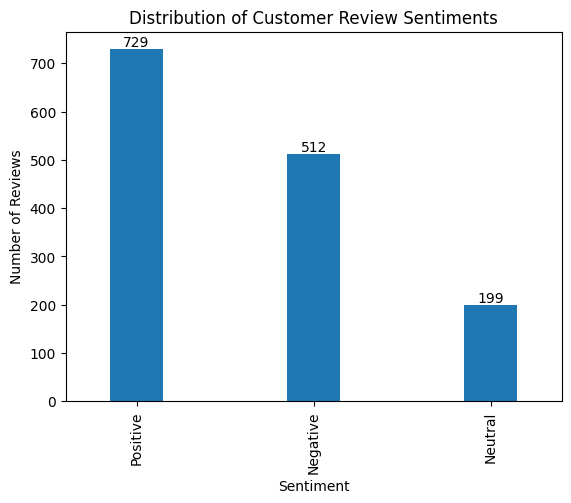

In [308]:
ax2 = df.sentiment.value_counts().sort_values(ascending=False).plot(kind='bar',width = 0.3)
for i in ax2.containers:
  ax2.bar_label(i)
  plt.title("Distribution of Customer Review Sentiments")
  plt.xlabel("Sentiment")
  plt.ylabel("Number of Reviews")
  plt.show()

Majority of the people had given the posiive review

#Word Cloud

word_cloud for the postive sentiment

In [309]:
from sklearn.feature_extraction.text import CountVectorizer

In [310]:
positive = df[df['sentiment'] == 'Positive']
positive.head()

,rating,sentiment,Review_length,text
2,4,Positive,403,overall get mobile launch date battery appreci...
14,5,Positive,229,good price segment unbox phone well price segm...
19,5,Positive,153,perfect phone price perfect phone good speed d...
28,5,Positive,780,budget package good phone buy bracket satisfyi...
33,5,Positive,376,light price complain real monster awesome disp...


In [311]:
cv = CountVectorizer(max_features=20)

X = cv.fit_transform(positive['text'])

positive_words = pd.DataFrame({
    'Word': cv.get_feature_names_out(),
    'Count': np.asarray(X.sum(axis=0)).ravel()
})

positive_words.sort_values(
    by='Count',
    ascending=False,
    inplace=True
)

positive_words

,Word,Count
6,good,1265
12,phone,1027
3,camera,617
0,battery,602
15,quality,352
13,price,343
17,samsung,335
10,mobile,233
8,life,229
4,day,223


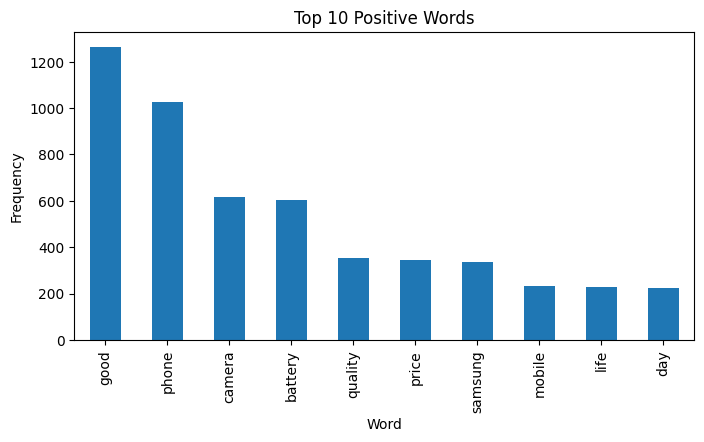

In [312]:
positive_words.head(10).plot(
    x='Word',
    y='Count',
    kind='bar',
    figsize=(8,4),
    legend=False
)

plt.title("Top 10 Positive Words")
plt.ylabel("Frequency")
plt.show()

In [313]:
from wordcloud import WordCloud

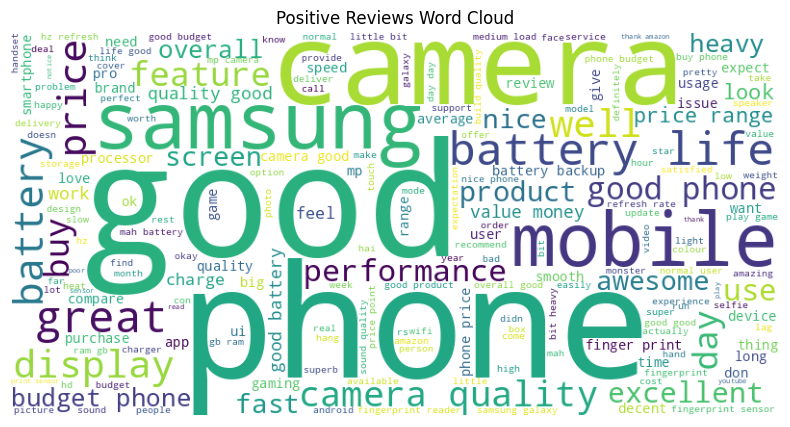

In [314]:
positive = " ".join(df[df['sentiment'] == 'Positive']['text'])

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(positive)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud)
plt.axis('off')
plt.title("Positive Reviews Word Cloud")
plt.show()

**word_cloud for the negative sentiment**

In [315]:
negative = df[df['sentiment'] == 'Negative']
negative.head()

,rating,sentiment,Review_length,text
0,1,Negative,59,horrible product disappointed overall performa...
3,1,Negative,377,big doesn work ghz wifi frequency ghz old scho...
4,1,Negative,179,money worth buy faulty software poor display q...
5,1,Negative,102,lagging slow purchase samsung phone phone lag ...
6,1,Negative,179,bad samsung mobile bad samsung mobile see sams...


In [316]:
cv = CountVectorizer(max_features=20)

X = cv.fit_transform(negative['text'])

negative_words = pd.DataFrame({
    'Word': cv.get_feature_names_out(),
    'Count': np.asarray(X.sum(axis=0)).ravel()
})

negative_words.sort_values(
    by='Count',
    ascending=False,
    inplace=True
)

negative_words

,Word,Count
12,phone,717
16,samsung,379
4,camera,315
1,bad,311
3,buy,305
11,mobile,303
15,quality,257
14,product,240
8,good,205
0,amazon,191


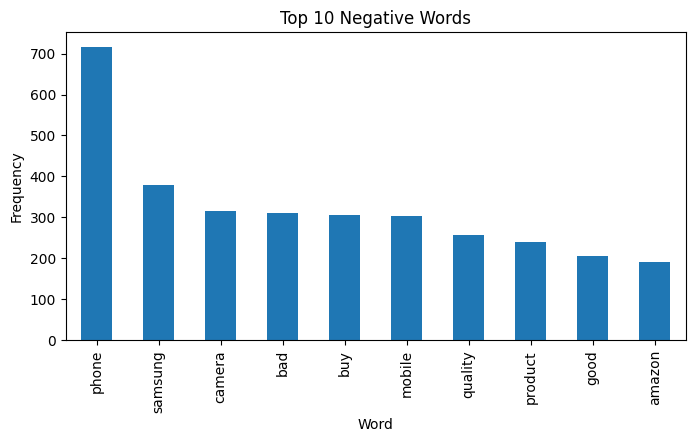

In [317]:
negative_words.head(10).plot(
    x='Word',
    y='Count',
    kind='bar',
    figsize=(8,4),
    legend=False
)

plt.title("Top 10 Negative Words")
plt.ylabel("Frequency")
plt.show()

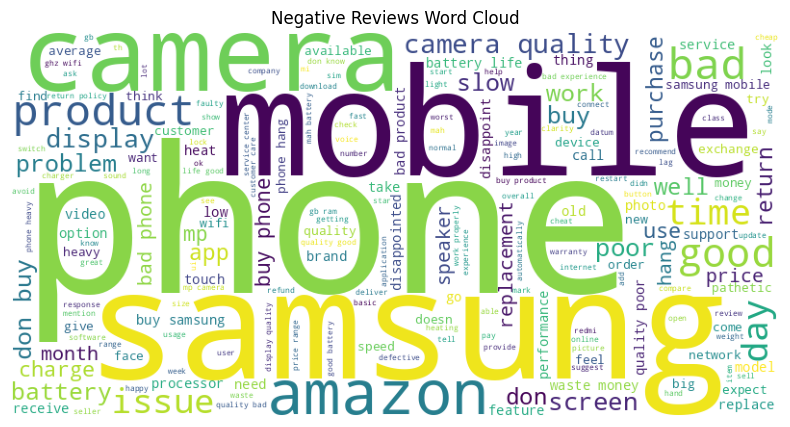

In [318]:
negative = " ".join(df[df['sentiment'] == 'Negative']['text'])

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(negative)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud)
plt.axis('off')
plt.title("Negative Reviews Word Cloud")
plt.show()

**word_cloud for the neutral sentiment**

In [319]:
neutral = df[df['sentiment'] == 'Neutral']
neutral.head()

,rating,sentiment,Review_length,text
1,3,Neutral,21,camera quality like megapixel camera quality low
23,3,Neutral,2490,impressive okay okay little price medium load ...
30,3,Neutral,872,good battery average performance pro big advan...
42,3,Neutral,450,marketing gimmick phone hz display lag browe n...
47,3,Neutral,1018,average phone bloatware samsung india force wr...


In [320]:
cv = CountVectorizer(max_features=20)

X = cv.fit_transform(neutral['text'])

neutral_words = pd.DataFrame({
    'Word': cv.get_feature_names_out(),
    'Count': np.asarray(X.sum(axis=0)).ravel()
})

neutral_words.sort_values(
    by='Count',
    ascending=False,
    inplace=True
)

neutral_words

,Word,Count
12,phone,284
7,good,230
4,camera,188
14,quality,123
2,battery,122
10,mobile,107
15,samsung,102
0,average,75
13,price,61
3,buy,56


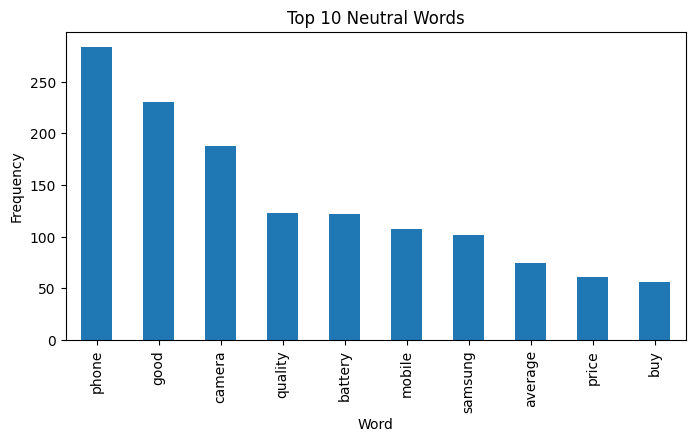

In [321]:
neutral_words.head(10).plot(
    x='Word',
    y='Count',
    kind='bar',
    figsize=(8,4),
    legend=False
)

plt.title("Top 10 Neutral Words")
plt.ylabel("Frequency")
plt.show()

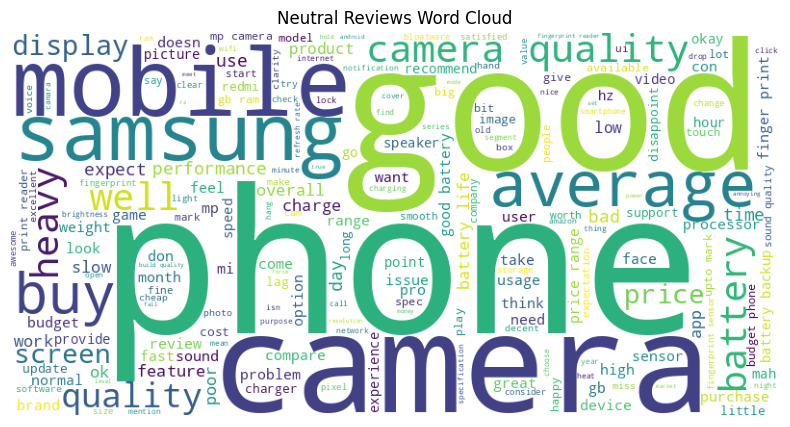

In [322]:
negative = " ".join(df[df['sentiment'] == 'Neutral']['text'])

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(negative)

plt.figure(figsize=(10,5))
plt.imshow(wordcloud)
plt.axis('off')
plt.title("Neutral Reviews Word Cloud")
plt.show()

In [323]:
# TF-IDF Vectorization: Converts text data into numerical feature vectors
# Label Encoding: Converts sentiment labels into numerical values

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

In [324]:
df.head()

,rating,sentiment,Review_length,text
0,1,Negative,59,horrible product disappointed overall performa...
1,3,Neutral,21,camera quality like megapixel camera quality low
2,4,Positive,403,overall get mobile launch date battery appreci...
3,1,Negative,377,big doesn work ghz wifi frequency ghz old scho...
4,1,Negative,179,money worth buy faulty software poor display q...


In [325]:
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(df['text']) # features/ input

label_encoder = LabelEncoder()
Y = label_encoder.fit_transform(df['sentiment']) # target / output

print(f"X shape: {X.shape}")
print(f"Y shape: {Y.shape}")

X shape: (1440, 4274)
Y shape: (1440,)


In [326]:
print(X)


<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 34663 stored elements and shape (1440, 4274)>
  Coords	Values
  (0, 1749)	0.6497856889028264
  (0, 2931)	0.27570552074842075
  (0, 1010)	0.4837010560685376
  (0, 2633)	0.32595115254650886
  (0, 2718)	0.33342016942320873
  (0, 3284)	0.2244663659872101
  (1, 541)	0.37764927650902524
  (1, 2995)	0.46711533527866234
  (1, 2133)	0.31401975245374514
  (1, 2293)	0.6116411935746348
  (1, 2194)	0.40800849610173245
  (2, 2633)	0.11111616692213362
  (2, 2718)	0.11366234146249576
  (2, 1510)	0.12103987334400743
  (2, 2356)	0.27138684133325663
  (2, 2074)	0.1976974713199441
  (2, 885)	0.20902738394797923
  (2, 336)	0.06624013989811812
  (2, 184)	0.2812222653470607
  (2, 259)	0.2812222653470607
  (2, 254)	0.12522467978336294
  (2, 1781)	0.14775899514687926
  (2, 3110)	0.15826321420177197
  (2, 3046)	0.15094101541012703
  (2, 522)	0.17079966259073906
  :	:
  (1438, 4158)	0.19010694754764615
  (1438, 1885)	0.19596138531914473
  (1438, 3557)

"We transformed the text data into numerical feature vectors using TF-IDF so that machine learning models can effectively process the textual information."

# Train_Test_split

In [327]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [328]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=100)

In [329]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(1152, 4274)
(1152,)
(288, 4274)
(288,)


# Model_Building

In [330]:
from sklearn.linear_model import LogisticRegressionCV

In [331]:
log_cv = LogisticRegressionCV(cv=5)
log_cv.fit(x_train, y_train)

LogisticRegressionCV(cv=5)

In [332]:
y_pred = log_cv.predict(x_train)
train_acc = accuracy_score(y_train, y_pred)
print(f"Training Accuracy: {train_acc}")

Training Accuracy: 0.9618055555555556


In [353]:
y_pred1 = log_cv.predict(x_test)
log_test_acc = accuracy_score(y_test, y_pred1)
print(f"Training Accuracy: {log_test_acc}")

Training Accuracy: 0.8090277777777778


# Decision_tree

In [334]:
from sklearn.tree import DecisionTreeClassifier
dec_tree_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=10,
    random_state=42
)

dec_tree_model.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=10, random_state=42)

In [335]:
y_pred = dec_tree_model.predict(x_train)
train_acc = accuracy_score(y_train, y_pred)
print(f"Training Accuracy: {train_acc}")

Training Accuracy: 0.8654513888888888


In [336]:
y_pred1 = dec_tree_model.predict(x_test)
test_acc = accuracy_score(y_test, y_pred1)
print(f"Training Accuracy: {test_acc}")

Training Accuracy: 0.6979166666666666


In [337]:
from sklearn.model_selection import GridSearchCV

In [338]:
dt_model = DecisionTreeClassifier(random_state=100)

In [339]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

In [340]:
grid_search = GridSearchCV(
    estimator=dt_model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=100),
             n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [5, 10, 15, 20],
                         'min_samples_leaf': [1, 2, 5],
                         'min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [341]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV Score:", grid_search.best_score_)

Best Parameters: {'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV Score: 0.7126783361565969


In [342]:
dt_model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=15,
    min_samples_leaf=1,
    min_samples_split=2,
    random_state=100
)

dt_model.fit(x_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=15, random_state=100)

In [343]:
y_pred = dt_model.predict(x_test)

In [344]:
dec_tree_accuracy = accuracy_score(y_test, y_pred)
print("Test Accuracy:", dec_tree_accuracy)

Test Accuracy: 0.6666666666666666


# Tree Ploting

In [345]:
from sklearn.tree import plot_tree

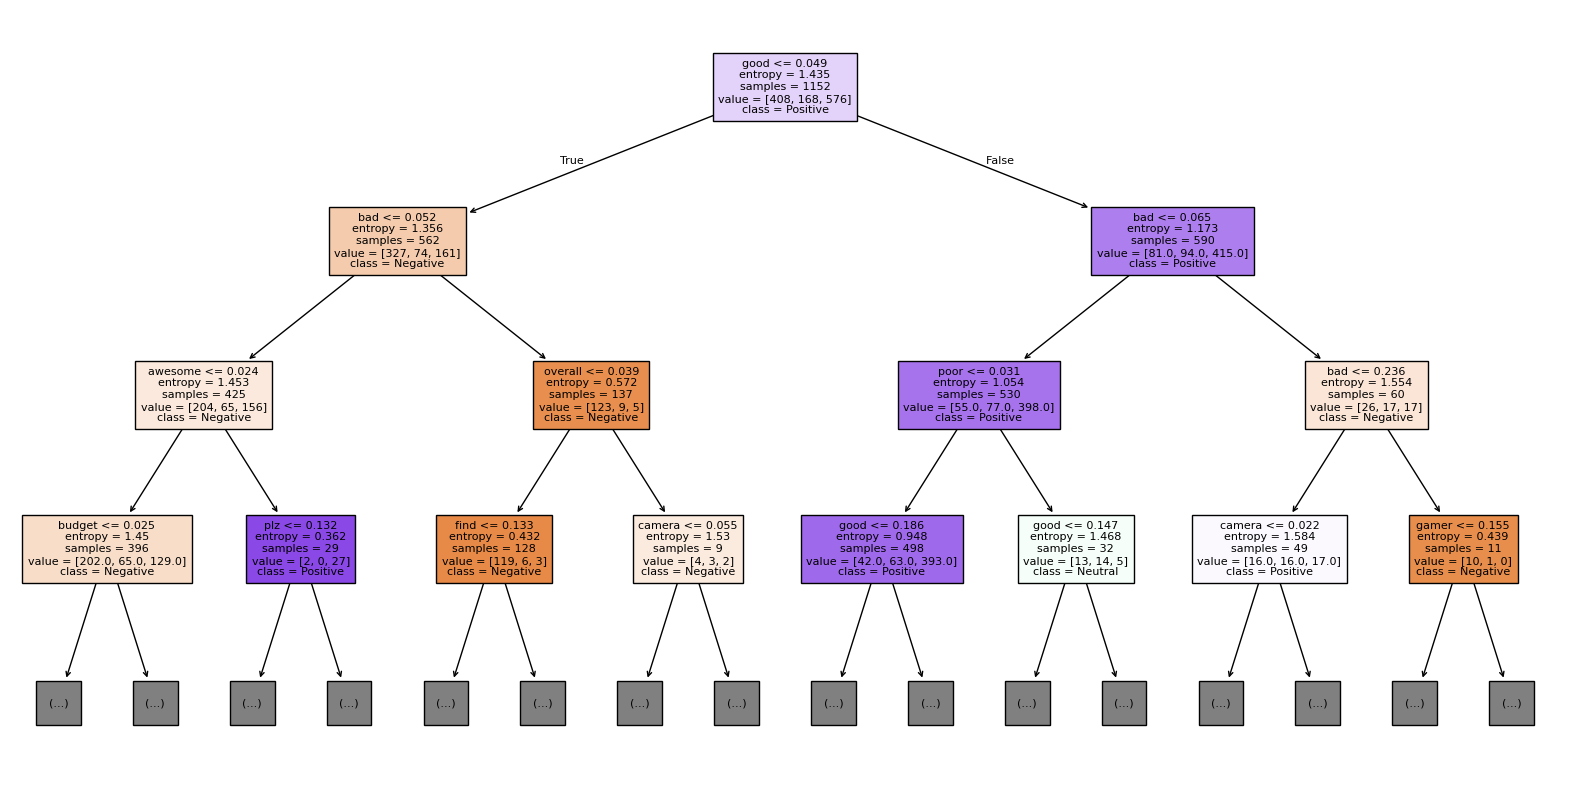

In [346]:
plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    max_depth=3,
    filled=True,
    feature_names=tfidf.get_feature_names_out(),
    class_names=label_encoder.classes_,
    fontsize=8
)

plt.show()

"Since our tuned Decision Tree has a maximum depth of 15, the complete tree is too large to visualize and interpret effectively. Therefore, we are displaying only the first three levels for better readability and understanding."

# Random_Forest

In [347]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    criterion='entropy',
    max_depth=15,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(x_train, y_train)

y_pred_rf = rf_model.predict(x_test)

In [348]:
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.7673611111111112


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'criterion': ['gini', 'entropy'],
    'max_depth': [10, 15, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(x_train, y_train)

print("Best Parameters:", grid_rf.best_params_)
print("Best CV Score:", grid_rf.best_score_)

In [ ]:
best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(x_test)
random_tree_acc = accuracy_score(y_test, y_pred_rf)
print("Test Accuracy:", random_tree_acc)

# Model_comparision

In [354]:
log_test_acc

0.8090277777777778

In [356]:
dec_tree_accuracy

0.6666666666666666

In [357]:
random_tree_acc

0.7777777777777778

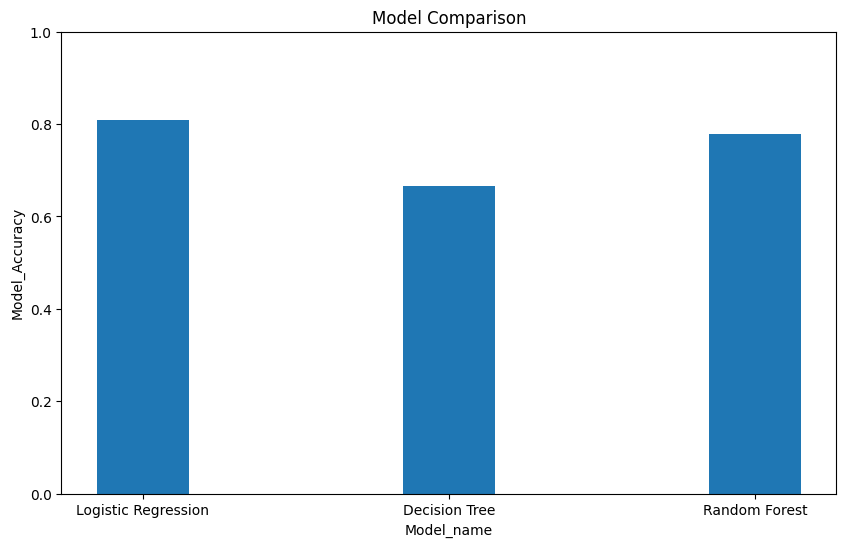

In [362]:
plt.figure(figsize=(10, 6))
models = ['Logistic Regression', 'Decision Tree', 'Random Forest']
accuracies = [log_test_acc, dec_tree_accuracy, random_tree_acc]

plt.bar(models, accuracies,width = 0.3)
plt.xlabel('Model_name')
plt.ylabel('Model_Accuracy')
plt.title('Model Comparison')
plt.ylim(0, 1)
plt.show()

Logistic_Regression is performing way better than other two models